# 🎬 Act 3 — 그래서 무엇을 할 것인가?
## 복합 리스크 점수 + 세그먼트별 차등 임계값 + 조기경보 룰

> **v3.2**: RED/YELLOW/GREEN 3단계 룰 + only_B 신상품 비즈니스 케이스

| 단계 | 내용 |
|------|------|
| 1 | Logistic Regression 기준 모델 (AUC) |
| 2 | 세그먼트별 차등 임계값 분석 |
| 3 | RED/YELLOW/GREEN 조기경보 룰 |
| 4 | only_B 신상품 비즈니스 임팩트 시뮬레이션 |

## 0. 데이터 로드

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.font_manager as fm
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import roc_auc_score, roc_curve, precision_recall_curve
from scipy.stats import norm
import os

for fname in ['AppleGothic','Apple SD Gothic Neo']:
    try:
        fp=fm.findfont(fm.FontProperties(family=fname),fallback_to_default=False)
        if fp: plt.rcParams['font.family']=fname; break
    except: pass
plt.rcParams['axes.unicode_minus']=False

DATA_DIR='home-credit-default-risk'
OUT_DIR ='.'

df=pd.read_csv(os.path.join(DATA_DIR,'application_train.csv'))
prev=pd.read_csv(os.path.join(DATA_DIR,'previous_application.csv'))
inst=pd.read_csv(os.path.join(DATA_DIR,'installments_payments.csv'))

df['age']=-df['DAYS_BIRTH']/365
df['employment_years']=np.where(df['DAYS_EMPLOYED']==365243,np.nan,-df['DAYS_EMPLOYED']/365)
df['ext_source_mean']=df[['EXT_SOURCE_1','EXT_SOURCE_2','EXT_SOURCE_3']].mean(axis=1)
df['ext_missing']=df[['EXT_SOURCE_1','EXT_SOURCE_2','EXT_SOURCE_3']].isnull().sum(axis=1)
df['credit_income_ratio']=(df['AMT_CREDIT']/df['AMT_INCOME_TOTAL']).clip(upper=20)
df['annuity_ratio']=df['AMT_ANNUITY']/df['AMT_INCOME_TOTAL']
df['log_income']=np.log1p(df['AMT_INCOME_TOTAL'])
df['phone_change_days']=-df['DAYS_LAST_PHONE_CHANGE']
df['id_publish_days']=-df['DAYS_ID_PUBLISH']
df['has_realty']=(df['FLAG_OWN_REALTY']=='Y').astype(int)
df['has_car']=(df['FLAG_OWN_CAR']=='Y').astype(int)
df['phone_recent']=(df['phone_change_days']<=365).astype(int)
df['id_recent']=(df['id_publish_days']<=1825).astype(int)
df['identity_recently_changed']=(df['phone_recent']+df['id_recent']==2).astype(int)

prev_agg=prev.groupby('SK_ID_CURR').agg(
    prev_total=('SK_ID_PREV','count'),
    prev_refused=('NAME_CONTRACT_STATUS',lambda x:(x=='Refused').sum())
).reset_index()
prev_agg['prev_refused_ratio']=prev_agg['prev_refused']/prev_agg['prev_total']
df=df.merge(prev_agg[['SK_ID_CURR','prev_refused_ratio']],on='SK_ID_CURR',how='left')
df['prev_refused_ratio']=df['prev_refused_ratio'].fillna(0)

inst['is_late']=(inst['DAYS_ENTRY_PAYMENT']>inst['DAYS_INSTALMENT']).astype(int)
inst_agg=inst.groupby('SK_ID_CURR').agg(
    inst_total=('is_late','count'),inst_late=('is_late','sum')).reset_index()
inst_agg['late_payment_ratio']=inst_agg['inst_late']/inst_agg['inst_total']
df=df.merge(inst_agg[['SK_ID_CURR','late_payment_ratio']],on='SK_ID_CURR',how='left')
df['late_payment_ratio']=df['late_payment_ratio'].fillna(0)

ext_thresh=df['ext_source_mean'].quantile(0.30)
df['risk_A']=(df['ext_source_mean']<=ext_thresh).astype(int)
df['risk_B']=(df['prev_refused_ratio']>0.3).astype(int)
df['only_B']=((df['risk_A']==0)&(df['risk_B']==1)).astype(int)
df['risk_AB']=((df['risk_A']==1)&(df['risk_B']==1)).astype(int)
df['segment']='general'
df.loc[df['only_B']==1,'segment']='only_B'
df.loc[df['risk_AB']==1,'segment']='risk_AB'
df.loc[(df['risk_A']==1)&(df['risk_AB']==0),'segment']='risk_A_only'
print(f'로드 완료: {len(df):,}명')

로드 완료: 307,511명


## 1. 기준 모델 — Logistic Regression (5-Fold CV AUC)

5-Fold CV AUC: 0.7379 ± 0.0026
Test AUC: 0.7379


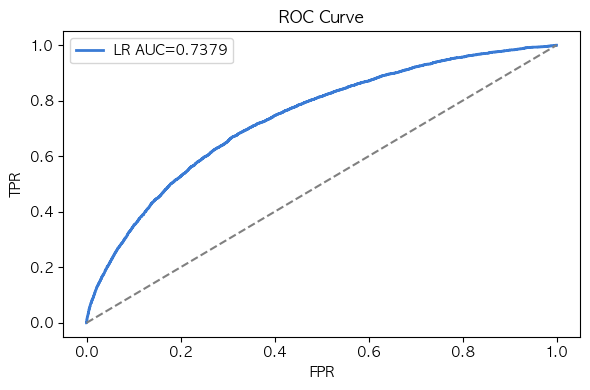

In [2]:
FEATS=['age','employment_years','log_income','credit_income_ratio','annuity_ratio',
       'ext_source_mean','EXT_SOURCE_2','EXT_SOURCE_3','ext_missing',
       'phone_change_days','id_publish_days','identity_recently_changed',
       'AMT_REQ_CREDIT_BUREAU_YEAR','prev_refused_ratio','late_payment_ratio',
       'has_realty','has_car','REGION_RATING_CLIENT_W_CITY',
       'DEF_60_CNT_SOCIAL_CIRCLE','CNT_FAM_MEMBERS']
mdf=df[FEATS+['TARGET','segment','only_B','risk_AB']].copy()
for c in FEATS: mdf[c]=mdf[c].fillna(mdf[c].median())

X=mdf[FEATS]; y=mdf['TARGET']
X_tr,X_te,y_tr,y_te,idx_tr,idx_te=train_test_split(
    X,y,mdf.index,test_size=0.2,random_state=42,stratify=y)
sc=StandardScaler()
X_tr_s=sc.fit_transform(X_tr); X_te_s=sc.transform(X_te)

lr=LogisticRegression(class_weight='balanced',max_iter=500,C=0.1,random_state=42)
cv_auc=cross_val_score(lr,sc.fit_transform(X),y,cv=5,scoring='roc_auc')
print(f'5-Fold CV AUC: {cv_auc.mean():.4f} ± {cv_auc.std():.4f}')

lr.fit(X_tr_s,y_tr)
prob_te=lr.predict_proba(X_te_s)[:,1]
auc_te=roc_auc_score(y_te,prob_te)
print(f'Test AUC: {auc_te:.4f}')

fpr,tpr,_=roc_curve(y_te,prob_te)
fig,ax=plt.subplots(figsize=(6,4))
ax.plot(fpr,tpr,color='#3a7bd5',lw=2,label=f'LR AUC={auc_te:.4f}')
ax.plot([0,1],[0,1],'--',color='gray')
ax.set_xlabel('FPR'); ax.set_ylabel('TPR')
ax.set_title('ROC Curve',fontweight='bold'); ax.legend()
plt.tight_layout(); plt.show()

## 2. ⭐ 세그먼트별 차등 임계값 분석

In [3]:
te_df=pd.DataFrame({'y':y_te.values,'prob':prob_te,
                    'segment':mdf.loc[idx_te,'segment'].values,
                    'only_B':mdf.loc[idx_te,'only_B'].values,
                    'risk_AB':mdf.loc[idx_te,'risk_AB'].values})

seg_thresh={}
print(f'{'세그먼트':<14}{'n':>6}{'실제연체율':>10}{'세그먼트AUC':>12}{'최적임계값':>11}{'단일(0.5)대비':>12}')
print('-'*70)
for seg in ['general','only_B','risk_AB','risk_A_only']:
    s=te_df[te_df['segment']==seg]
    if len(s)<50 or s['y'].sum()<5: continue
    try: auc_s=roc_auc_score(s['y'],s['prob'])
    except: auc_s=float('nan')
    prec,rec,thresh=precision_recall_curve(s['y'],s['prob'])
    f1=2*prec*rec/(prec+rec+1e-8)
    best_t=thresh[np.argmax(f1[:-1])] if len(thresh)>0 else 0.5
    seg_thresh[seg]=best_t
    print(f'{seg:<14}{len(s):>6,}{s["y"].mean()*100:>9.2f}%{auc_s:>12.4f}{best_t:>11.4f}{best_t-0.5:>+12.4f}')

# only_B 오분류 비교
ob=te_df[te_df['only_B']==1]
good_mask=ob['y']==0
fp_s=(ob.loc[good_mask,'prob']>=0.5).sum()
fp_seg=(ob.loc[good_mask,'prob']>=seg_thresh.get('only_B',0.5)).sum()
n_good=good_mask.sum()
print(f'\n회복형 우량 고객 오분류율:')
print(f'  단일 임계값(0.5):  {fp_s/n_good*100:.1f}% ({fp_s:,}명 거절)')
print(f'  차등 임계값:       {fp_seg/n_good*100:.1f}% ({fp_seg:,}명 거절)')
print(f'  개선: {fp_s-fp_seg:,}명 추가로 올바르게 분류')

세그먼트               n     실제연체율     세그먼트AUC      최적임계값   단일(0.5)대비
----------------------------------------------------------------------
general       37,496     4.29%      0.6576     0.4649     -0.0351
only_B         5,591     6.94%      0.6666     0.5470     +0.0470
risk_AB        3,644    20.99%      0.6383     0.7495     +0.2495
risk_A_only   14,772    14.92%      0.6461     0.6811     +0.1811

회복형 우량 고객 오분류율:
  단일 임계값(0.5):  29.1% (1,512명 거절)
  차등 임계값:       18.6% (966명 거절)
  개선: 546명 추가로 올바르게 분류


## 3. 🚨 RED/YELLOW/GREEN 조기경보 룰

In [4]:
dr_all=df['TARGET'].mean()*100
ext_q10=df['ext_source_mean'].quantile(0.10)
ext_q30=df['ext_source_mean'].quantile(0.30)

dr_red1=df[df['ext_source_mean']<=ext_q10]['TARGET'].mean()*100
dr_red2=df[df['ext_missing']>=2]['TARGET'].mean()*100
dr_red3=df[df['prev_refused_ratio']>0.5]['TARGET'].mean()*100
dr_yellow_late=df[df['late_payment_ratio']>df['late_payment_ratio'].quantile(0.8)]['TARGET'].mean()*100
dr_yellow_irc=df[df['identity_recently_changed']==1]['TARGET'].mean()*100
dr_green=df[df['only_B']==1]['TARGET'].mean()*100

rules=[
    ('🚨 RED — 즉시 강화 심사',[
        f'EXT_MEAN ≤ {ext_q10:.3f} (하위 10%) → 연체율 {dr_red1:.1f}%',
        f'EXT 결측 2개 이상 → 연체율 {dr_red2:.1f}%',
        f'과거 거절 50%↑ → 연체율 {dr_red3:.1f}%',
    ],'#e05c5c'),
    ('🟡 YELLOW — 추가 확인',[
        f'EXT_MEAN {ext_q10:.3f}~{ext_q30:.3f} (하위 10~30%)',
        f'할부 연체 상위 20% → 연체율 {dr_yellow_late:.1f}%',
        f'identity_recently_changed → 연체율 {dr_yellow_irc:.1f}%',
        '20~25세 + 직업 없음',
    ],'#f5a623'),
    ('🟢 GREEN — 완화 심사 (신상품 대상)',[
        f'only_B 회복형: 과거 거절 + EXT ≥ {ext_q30:.3f}',
        f'  → 연체율 {dr_green:.2f}% (전체 평균 {dr_all:.2f}% 이하)',
        f'  → 한도제한 신상품 우선 제안',
        '  → 기존 거절 기준 완화 검토 가능',
    ],'#2fa896'),
]

print('='*60)
print('Act 3 — 세그먼트별 조기경보 룰')
print('='*60)
for title,rule_list,color in rules:
    print(f'\n{title}')
    print('-'*50)
    for r in rule_list: print(f'  • {r}')

Act 3 — 세그먼트별 조기경보 룰

🚨 RED — 즉시 강화 심사
--------------------------------------------------
  • EXT_MEAN ≤ 0.304 (하위 10%) → 연체율 22.9%
  • EXT 결측 2개 이상 → 연체율 9.9%
  • 과거 거절 50%↑ → 연체율 15.9%

🟡 YELLOW — 추가 확인
--------------------------------------------------
  • EXT_MEAN 0.304~0.439 (하위 10~30%)
  • 할부 연체 상위 20% → 연체율 11.3%
  • identity_recently_changed → 연체율 12.1%
  • 20~25세 + 직업 없음

🟢 GREEN — 완화 심사 (신상품 대상)
--------------------------------------------------
  • only_B 회복형: 과거 거절 + EXT ≥ 0.439
  •   → 연체율 6.83% (전체 평균 8.07% 이하)
  •   → 한도제한 신상품 우선 제안
  •   → 기존 거절 기준 완화 검토 가능


## 4. 💰 only_B 신상품 비즈니스 임팩트 시뮬레이션

In [5]:
n_onlyB=df['only_B'].sum()
dr_onlyB=df[df['only_B']==1]['TARGET'].mean()
n_good_onlyB=int(n_onlyB*(1-dr_onlyB))
avg_credit=df['AMT_CREDIT'].median()
margin_rate=0.03
potential_rev=n_good_onlyB*avg_credit*margin_rate

n_AB=df['risk_AB'].sum()
dr_AB=df[df['risk_AB']==1]['TARGET'].mean()
n_AB_bad=int(n_AB*dr_AB)
prevented_loss=n_AB_bad*avg_credit*0.5

print('='*60)
print('💰 비즈니스 임팩트 시뮬레이션')
print('='*60)
print(f'\n[신상품 기회 — only_B 회복형]')
print(f'  전체 회복형: {n_onlyB:,}명')
print(f'  실제 우량:   {n_good_onlyB:,}명 ({(1-dr_onlyB)*100:.1f}%)')
print(f'  평균 대출금: {avg_credit:,.0f}')
print(f'  추가 수익(3% 마진 기준): {potential_rev:,.0f}')
print(f'\n[리스크 절감 — A∩B 조기경보]')
print(f'  A∩B 고위험: {n_AB:,}명 (연체율 {dr_AB*100:.1f}%)')
print(f'  예상 연체자: {n_AB_bad:,}명')
print(f'  예방 손실: {prevented_loss:,.0f}')
print(f'\n[3 Acts 전략 요약]')
print(f'  Act 1: Top 5 시그널 활용 → 심사 기준 고도화')
print(f'  Act 2: 4개 클러스터 → 세그먼트별 차등 심사')
print(f'  Act 3: 회복형 신상품 + 조기경보 = 매출↑ + 리스크↓')

results=pd.DataFrame({
    '항목':['only_B 전체','only_B 우량','A∩B 전체','A∩B 예상연체'],
    '인원':[n_onlyB,n_good_onlyB,n_AB,n_AB_bad],
    '연체율':[f'{dr_onlyB*100:.2f}%','-',f'{dr_AB*100:.2f}%','-'],
})
results.to_csv(os.path.join(OUT_DIR,'act3_business_impact.csv'),index=False,encoding='utf-8-sig')
print('\n✅ 저장: act3_business_impact.csv')

💰 비즈니스 임팩트 시뮬레이션

[신상품 기회 — only_B 회복형]
  전체 회복형: 28,211명
  실제 우량:   26,285명 (93.2%)
  평균 대출금: 513,531
  추가 수익(3% 마진 기준): 404,944,870

[리스크 절감 — A∩B 조기경보]
  A∩B 고위험: 18,621명 (연체율 21.2%)
  예상 연체자: 3,949명
  예방 손실: 1,013,966,960

[3 Acts 전략 요약]
  Act 1: Top 5 시그널 활용 → 심사 기준 고도화
  Act 2: 4개 클러스터 → 세그먼트별 차등 심사
  Act 3: 회복형 신상품 + 조기경보 = 매출↑ + 리스크↓

✅ 저장: act3_business_impact.csv
